# Bayesian inference for the stopped-source $C_{p_T}$ model, in JAX

Fits the two-centrality STAR $C_{p_T}$ excitation function with the **exact finite-$N_s$ AoR
correlator**, Eqs. (28)-(31):

$$\frac{\sqrt{\langle\Delta p_{T,i}\Delta p_{T,j}\rangle_{\rm AoR}}}{\langle p_T\rangle_{\rm AoR}}
=\sqrt{\frac{\left(1+\frac{1}{N_s\nu}\right)\mathcal{I}_2(N_s,\lambda)-\frac{1}{N_s}\left(1+\frac{1}{\nu}\right)\mathcal{J}_2(N_s,\lambda)}{\left[\mathcal{I}_1(N_s,\lambda)\right]^2}-1}$$

$\lambda=\langle n\rangle-1$, and $\nu$ is the Gamma shape of the source momentum
($\mathrm{Var}(q)/\langle q\rangle^2=1/\nu$). The acceptance cancels and does not appear.

Two things have to be dealt with before this will run under NUTS, and Section 1 does both:

1. **The Poisson sums will not `jit`.** Their truncation window depends on $N_s\lambda$, so the
   array shape depends on the parameters. Section 2 replaces them with integral representations
   on fixed domains -- exact, and differentiable.
2. **float32 is not enough.** The bracket is a difference of nearly equal $O(1)$ terms whose
   result is $O(10^{-4})$, so single precision loses it entirely; at $N_s=60,\langle n\rangle=8$
   it overflows and returns NaN, which NUTS reports as
   `ValueError: Cannot find valid initial parameters`. **`jax_enable_x64` is mandatory**, and the
   first cell sets it before anything else touches JAX.

## 1. Setup

Order matters in this cell. `set_host_device_count` must precede JAX backend initialisation or
the four chains fall back to running sequentially, and `jax_enable_x64` must precede any array
creation or it silently has no effect.

In [ ]:
# !pip install -q "jax[cpu]" numpyro arviz

import os
# must be set before the JAX backend initialises, or chains run sequentially
os.environ.setdefault('XLA_FLAGS', '--xla_force_host_platform_device_count=4')

import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.laguerre import laggauss
from numpy.polynomial.legendre import leggauss

try:
    import numpyro
    numpyro.set_host_device_count(4)
    import jax
    jax.config.update('jax_enable_x64', True)      # REQUIRED -- see the note above
    import jax.numpy as jnp
    import numpyro.distributions as dist
    from numpyro.infer import MCMC, NUTS
    HAS_JAX = True
    print('jax', jax.__version__, '| x64', jax.config.jax_enable_x64,
          '| devices', jax.local_device_count())
except ImportError:
    HAS_JAX = False
    print('JAX not found -- Sections 1-3 still run; Sections 4-6 need it.')

NZ, NS_LEG = 96, 40          # quadrature nodes; fixed, so the model is jittable

### The data

STAR Au+Au, HEPData `10.17182/hepdata.181421.v1`, Fig. 4. `y` is
$\sqrt{C_{p_T}}/\langle\langle p_T\rangle\rangle$ in percent, `err` is stat and sys in quadrature.
`ntot` is the $4\pi$ multiplicity of **all** particles per participant, so $N_s$ and
$\langle n\rangle$ are $4\pi$ all-particle quantities.

In [2]:
ROWS = [
    (   3.0,  1.3800,  0.1226, 0,   327.80,    616.80,   1.7589, "FXT"),
    (   3.2,  1.3300,  0.1513, 0,   329.20,    628.00,   1.9519, "FXT"),
    (   3.5,  1.0800,  0.0985, 0,   331.00,    645.00,   2.2555, "FXT"),
    (   3.9,  0.9400,  0.1170, 0,   332.20,    664.90,   2.6858, "FXT"),
    (   4.5,  0.8400,  0.1020, 0,   334.40,    693.00,   3.3832, "FXT"),
    (   5.2,  0.5400,  0.1237, 0,   336.40,    720.80,   4.2720, "FXT"),
    (   7.7,  0.2100,  0.3353, 0,   341.20,    797.60,   5.1629, "BES-I"),
    (   7.7,  0.4500,  0.0860, 0,   341.20,    797.60,   5.1629, "COL"),
    (   7.7,  0.5200,  0.1442, 0,   341.20,    797.60,   5.1629, "FXT"),
    (  11.5,  0.7700,  0.0640, 0,   341.00,    809.50,   6.1898, "BES-I"),
    (  14.5,  0.8730,  0.0610, 0,   342.26,    821.15,   6.8096, "BES-I"),
    (  19.6,  0.9390,  0.0411, 0,   341.30,    825.40,   7.7092, "BES-I"),
    (  27.0,  0.9670,  0.0277, 0,   344.00,    855.50,   8.9608, "BES-I"),
    (  39.0,  1.0290,  0.0313, 0,   344.50,    880.20,  10.6502, "BES-I"),
    (  62.4,  1.0840,  0.0273, 0,   345.90,    912.50,  13.0014, "BES-I"),
    ( 200.0,  1.1850,  0.0335, 0,   352.00,   1077.00,  19.9820, "BES-I"),
    (   3.0,  3.2300,  0.0821, 1,    92.40,    122.60,   1.7589, "FXT"),
    (   3.2,  3.3900,  0.1201, 1,    92.70,    124.40,   1.9519, "FXT"),
    (   3.5,  2.7800,  0.1301, 1,    93.60,    127.20,   2.2555, "FXT"),
    (   3.9,  2.7800,  0.1501, 1,    95.30,    132.70,   2.6858, "FXT"),
    (   4.5,  2.8000,  0.1400, 1,    96.50,    137.50,   3.3832, "FXT"),
    (   5.2,  2.3500,  0.1401, 1,    97.90,    143.00,   4.2720, "FXT"),
    (   7.7,  1.7400,  0.0849, 1,   101.60,    158.70,   5.1629, "BES-I"),
    (   7.7,  1.9100,  0.1400, 1,   101.60,    158.70,   5.1629, "FXT"),
    (   7.7,  2.0500,  0.1401, 1,   101.60,    158.70,   5.1629, "COL"),
    (  11.5,  1.8600,  0.0894, 1,   101.60,    160.00,   6.1898, "BES-I"),
    (  14.5,  1.9070,  0.0720, 1,   102.09,    162.53,   6.8096, "BES-I"),
    (  19.6,  1.9500,  0.0709, 1,   103.00,    166.20,   7.7092, "BES-I"),
    (  27.0,  2.0400,  0.0706, 1,   103.60,    169.90,   8.9608, "BES-I"),
    (  39.0,  2.1420,  0.0702, 1,   104.60,    174.60,  10.6502, "BES-I"),
    (  62.4,  2.0650,  0.0614, 1,   106.00,    181.90,  13.0014, "BES-I"),
    ( 200.0,  2.1310,  0.0604, 1,   112.40,    216.30,  19.9820, "BES-I"),
]
E_ALL    = np.array([r[0] for r in ROWS])
Y_ALL    = np.array([r[1] for r in ROWS])
ERR_ALL  = np.array([r[2] for r in ROWS])
CENT_ALL = np.array([r[3] for r in ROWS], dtype=int)
NPART_ALL= np.array([r[4] for r in ROWS])
NTOT_ALL = np.array([r[6] for r in ROWS])
TAG_ALL  = np.array([r[7] for r in ROWS])

# the 7.7 GeV BES-I 0-5% point is 0.21 +- 0.34 and carries no information
KEEP = ~((E_ALL == 7.7) & (CENT_ALL == 0) & (TAG_ALL == 'BES-I'))
E, Y, ERR, CENT, NPART, NTOT = (a[KEEP] for a in (E_ALL, Y_ALL, ERR_ALL, CENT_ALL, NPART_ALL, NTOT_ALL))
UE   = np.unique(E)
EIDX = np.searchsorted(UE, E)
print('%d points kept, %d distinct energies' % (len(E), len(UE)))

31 points kept, 14 distinct energies


## 2. From Poisson sums to fixed-domain integrals

Using

$$\frac1N=\int_0^1 t^{N-1}dt,\quad \frac{1}{N(N-1)}=\int_0^1(1-t)t^{N-2}dt,\quad
\frac{2}{k+2}=2\int_0^1 s^{k+1}ds,\quad \mathbb{E}[t^K]=e^{m(t-1)}$$

the three expectations become

$$\mathcal{I}_1=\int_0^1 t^{N_s-1}e^{N_s\lambda(t-1)}dt,\qquad
\mathcal{I}_2=\int_0^1(1-t)t^{N_s-2}e^{N_s\lambda(t-1)}dt$$
$$\mathcal{J}_2=2\int_0^1\!\!\int_0^1(1-t)\,s\,t^{N_s-2}e^{\lambda(st-1)}e^{(N_s-1)\lambda(t-1)}ds\,dt$$

which agree with the discrete sums to $10^{-13}$. Substituting $t=e^{-u}$, $u=z/\langle N\rangle$
with $\langle N\rangle=N_s(1+\lambda)$, the $\mathcal{I}_1$ exponent collapses to

$$-\frac{zN_s}{\langle N\rangle}+N_s\lambda(t-1)+z \;=\; N_s\lambda\,\rho(u),\qquad
\rho(u)=u+e^{-u}-1$$

an exact cancellation of the two $O(z)$ terms. Computing $\rho$ directly would reintroduce that
cancellation at small $u$, so the code uses its series $\rho=u^2/2-u^3/6+u^4/24$ below
$u=10^{-4}$. Likewise $\log(1-t)$ is evaluated as $\log(-\mathrm{expm1}(-u))$, which is exact,
rather than $\mathrm{log1p}(-e^{-u})$, which is not. The quadrature weights are carried in
logarithms so that a vanishing weight can never multiply a diverging exponential.

In [3]:
def make_forward(xp):
    # Correlator on backend `xp` (numpy or jax.numpy). Node counts are compile-time constants,
    # so every shape below is static and the whole thing jits.
    z_np,  wz_np = laggauss(NZ)
    s_np,  ws_np = leggauss(NS_LEG)
    s_np = 0.5*(s_np + 1.0); ws_np = 0.5*ws_np
    # log weights: avoids 0 * inf when a tiny weight meets a large exponential
    z, lwz, s, lws = (xp.asarray(a) for a in (z_np, np.log(wz_np), s_np, np.log(ws_np)))

    def rho(u):
        # u + exp(-u) - 1, by series where the direct form would cancel
        small = u < 1e-4
        us = xp.where(small, 1e-4, u)
        return xp.where(small, u*u*(0.5 - u/6.0 + u*u/24.0), us + xp.exp(-us) - 1.0)

    def sums(Ns, lam):
        Ns  = xp.asarray(Ns)[..., None]
        lam = xp.asarray(lam)[..., None]
        M   = Ns*(1.0 + lam)                     # <N>
        u   = z/M
        r   = rho(u)
        log1mt = xp.log(-xp.expm1(-u))           # = log(1 - t), exact
        e1  = Ns*lam*r                           # the I1 exponent, after the cancellation
        i1 = xp.exp(lwz + e1).sum(-1)/M[..., 0]
        i2 = xp.exp(lwz + log1mt + e1 + u).sum(-1)/M[..., 0]
        A  = log1mt + u + lam*u + (Ns - 1.0)*lam*r
        Bm = xp.log(s) + lam[..., None]*(s*xp.exp(-u)[..., None] - 1.0)
        j2 = 2.0*xp.exp(lwz[:, None] + lws + A[..., None] + Bm).sum((-1, -2))/M[..., 0]
        return i1, i2, j2

    def sqrtC_pct(Ns, nbar, nu):
        i1, i2, j2 = sums(Ns, nbar - 1.0)
        num = (1.0 + 1.0/(Ns*nu))*i2 - (1.0/Ns)*(1.0 + 1.0/nu)*j2
        return 100.0*xp.sqrt(xp.clip(num/i1**2 - 1.0, 1e-30, None))

    return sums, sqrtC_pct

sums_np, fwd_np = make_forward(np)
print('forward model built on NumPy')

forward model built on NumPy


## 3. Validation

None of these need JAX.

In [4]:
# (a) reproduce the point-by-point solutions; the last column is the measurement
print('     Ns     <n>    nu  | model %  | measured %')
for Ns, nb, obs in [(403., 1.43, 1.38), (1289., 1.12, 0.54), (1608., 1.10, 0.45),
                    (1259., 5.59, 1.19), (116., 1.82, 2.78), (394., 5.70, 2.13)]:
    print('%9.0f %6.2f %5.2f  | %7.4f  | %7.2f'
          % (Ns, nb, 3.41, fwd_np(np.array([Ns]), np.array([nb]), 3.41)[0], obs))

# (b) chi2 at the grid best fit -- reference 9.03
x  = 1.0 + (3.24 - 1.0)/(1.0 + np.exp(-(E - 5.03)/0.63))
mu = fwd_np(x*NPART, np.clip(NTOT/x, 1.0005, None), 3.41)
chi2 = (((mu - Y)/ERR)**2).sum()
print('\nchi2 = %.1f   chi2/dof = %.2f   (grid reference 9.03)' % (chi2, chi2/(len(E) - 4)))

# (c) stability across the whole range the priors can reach
print('\nspot checks over the prior range:')
for Ns, nb in ((60., 1.0005), (60., 25.), (1289., 1.12), (3900., 25.)):
    print('   Ns=%6.0f  <n>=%7.4f  ->  %.6f %%'
          % (Ns, nb, fwd_np(np.array([Ns]), np.array([nb]), 3.41)[0]))

     Ns     <n>    nu  | model %  | measured %
      403   1.43  3.41  |  1.3806  |    1.38
     1289   1.12  3.41  |  0.5482  |    0.54
     1608   1.10  3.41  |  0.4584  |    0.45
     1259   5.59  3.41  |  1.1860  |    1.19
      116   1.82  3.41  |  2.7770  |    2.78
      394   5.70  3.41  |  2.1325  |    2.13

chi2 = 243.4   chi2/dof = 9.01   (grid reference 9.03)

spot checks over the prior range:
   Ns=    60  <n>= 1.0005  ->  0.187862 %
   Ns=    60  <n>=25.0000  ->  6.692248 %
   Ns=  1289  <n>= 1.1200  ->  0.548168 %
   Ns=  3900  <n>=25.0000  ->  0.829550 %


## 4. Model A -- switch, one $F$ per centrality class

$$N_s/N_{\rm part}=1+(F_c-1)\,\sigma\!\left(\frac{\sqrt{s}-E_{\rm tr}}{w}\right),\qquad
\langle n\rangle=\frac{N_{4\pi}(E)\,e^{\delta_e}}{N_s/N_{\rm part}}$$

with $\delta_e$ a per-energy log-normal nuisance (25%) on the yield -- which is how that
systematic should enter, rather than as a hand-drawn band. About 20 parameters.

Grid reference, single $F$: $F=3.24\pm0.11$, $E_{\rm tr}=5.03\pm0.06$, $w=0.63\pm0.03$,
$\nu=3.41\pm0.20$, $\chi^2/{\rm dof}=9.03$. Here $F$ is per class, so expect $F_0>F_1$; the
point-by-point extraction gives $3.48\pm0.24$ and $2.94\pm0.27$.

In [12]:
def switch_model():
    _, fwd = make_forward(jnp)
    Ej, Yj, ERRj = jnp.asarray(E), jnp.asarray(Y), jnp.asarray(ERR)
    NPj, NTj = jnp.asarray(NPART), jnp.asarray(NTOT)
    cent, eidx, nE = jnp.asarray(CENT), jnp.asarray(EIDX), len(UE)

    F   = numpyro.sample('F',   dist.Uniform(1.05, 8.0).expand([2]).to_event(1))
    Etr = numpyro.sample('Etr', dist.LogUniform(2.5, 30.0))
    w   = numpyro.sample('w',   dist.Uniform(0.2, 6.0))
    nu  = numpyro.sample('nu',  dist.LogUniform(1.5, 12.0))
    numpyro.deterministic('relvar', 1.0/nu)
    with numpyro.plate('energies', nE):
        d = numpyro.sample('d', dist.Normal(0.0, 0.25))

    x  = 1.0 + (F[cent] - 1.0)/(1.0 + jnp.exp(-(Ej - Etr)/w))
    nb = NTj*jnp.exp(d)[eidx]/x
    Ns = x*NPj
    numpyro.deterministic('Ns', Ns)
    numpyro.deterministic('nbar', nb)
    mu = fwd(Ns, jnp.clip(nb, 1.0005, None), nu)
    numpyro.sample('obs', dist.Normal(mu, ERRj), obs=Yj)

if HAS_JAX:
    # sanity check before sampling: the log-density must be finite at a sensible point
    from numpyro.infer.util import log_density
    import numpyro.handlers as H
    pt = dict(F=jnp.array([3.4, 2.9]), Etr=5.0, w=0.63, nu=3.41, d=jnp.zeros(len(UE)))
    ld, _ = log_density(switch_model, (), {}, pt)
    print('log density at the reference point: %.2f  (finite: %s)' % (ld, bool(jnp.isfinite(ld))))

log density at the reference point: -48.24  (finite: True)


In [ ]:
if HAS_JAX:
    mcmc = MCMC(NUTS(switch_model, target_accept_prob=0.9, max_tree_depth=12),
                num_warmup=1500, num_samples=3000, num_chains=4)
    mcmc.run(jax.random.PRNGKey(0))
    mcmc.print_summary(exclude_deterministic=True)

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

  0%|          | 0/4500 [00:00<?, ?it/s]

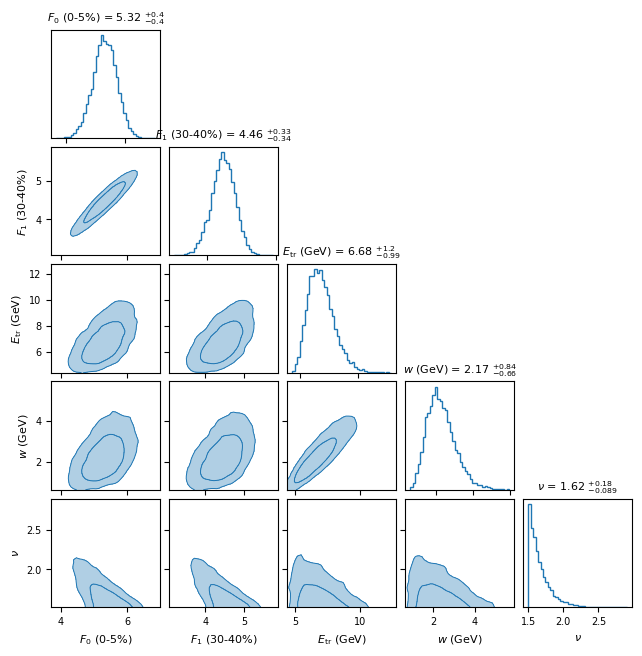

Var(q)/<q>^2 = 0.618 +0.036 -0.063   (thermal band 0.273-0.500)
F_0 - F_1    = +0.87 +- 0.10


In [10]:
# Corner plot drawn straight from the posterior samples -- deliberately NOT via
# arviz.plot_pair, which in arviz 1.x routes through arviz_plots and rejects `figsize`
# ("Keyword arguments ... have no active aesthetic mapped to them").  This works on any version.
from scipy.ndimage import gaussian_filter

def corner_from_samples(samples, names, labels=None, bins=40, smooth=1.0,
                        figsize=(7.5, 7.5), color='tab:blue'):
    cols, auto = [], []
    for n in names:
        a = np.asarray(samples[n])
        if a.ndim == 1:
            cols.append(a); auto.append(n)
        else:                                      # vector site -> one column per component
            for k in range(a.shape[1]):
                cols.append(a[:, k]); auto.append('%s[%d]' % (n, k))
    labels = labels or auto
    d = len(cols)

    def levels(H):
        f = np.sort(H.ravel())[::-1]; c = np.cumsum(f)/f.sum()
        return [f[np.searchsorted(c, q)] for q in (0.95, 0.68)]

    fig, axs = plt.subplots(d, d, figsize=figsize)
    for i in range(d):
        for j in range(d):
            ax = axs[i, j]
            if j > i:
                ax.axis('off'); continue
            if i == j:
                ax.hist(cols[i], bins=bins, color=color, histtype='step', density=True)
                ax.set_yticks([])
                q = np.percentile(cols[i], [16, 50, 84])
                ax.set_title('%s = %.3g $^{+%.2g}_{-%.2g}$'
                             % (labels[i], q[1], q[2]-q[1], q[1]-q[0]), fontsize=8)
            else:
                H, xe, ye = np.histogram2d(cols[j], cols[i], bins=bins)
                if smooth: H = gaussian_filter(H, smooth)
                lv = levels(H)
                xc, yc = 0.5*(xe[1:]+xe[:-1]), 0.5*(ye[1:]+ye[:-1])
                ax.contourf(xc, yc, H.T, levels=lv + [H.max()*1.001],
                            colors=[color, color], alpha=0.35)
                ax.contour(xc, yc, H.T, levels=lv, colors=color, linewidths=0.7)
            if i == d-1: ax.set_xlabel(labels[j], fontsize=8)
            else: ax.set_xticklabels([])
            if j == 0 and i > 0: ax.set_ylabel(labels[i], fontsize=8)
            elif i != j: ax.set_yticklabels([])
            ax.tick_params(labelsize=7)
    fig.subplots_adjust(wspace=0.08, hspace=0.08)
    return fig

if HAS_JAX:
    s = mcmc.get_samples()
    fig = corner_from_samples(s, ['F', 'Etr', 'w', 'nu'],
                              labels=[r'$F_0$ (0-5%)', r'$F_1$ (30-40%)',
                                      r'$E_{\rm tr}$ (GeV)', r'$w$ (GeV)', r'$\nu$'])
    plt.show()
    rv = 1.0/np.asarray(s['nu'])
    q16, q50, q84 = np.percentile(rv, [16, 50, 84])
    print('Var(q)/<q>^2 = %.3f +%.3f -%.3f   (thermal band 0.273-0.500)'
          % (q50, q84 - q50, q50 - q16))
    print('F_0 - F_1    = %+.2f +- %.2f'
          % ((np.asarray(s['F'])[:, 0] - np.asarray(s['F'])[:, 1]).mean(),
             (np.asarray(s['F'])[:, 0] - np.asarray(s['F'])[:, 1]).std()))

## 6. Notes

* **float64 is not optional.** In float32 the forward model is wrong by 1-23% and returns NaN at
  $N_s=60,\langle n\rangle=8$; NUTS then reports `Cannot find valid initial parameters`. With x64
  and the rewrites of Section 2 the quadrature is good to $5\times10^{-6}$ over
  $N_s=60$-$3900$, $\langle n\rangle=1.0005$-$25$, $\nu=1.5$-$12$ (108 combinations checked).
* **The clip at $\langle n\rangle=1.0005$.** The bracket loses precision as $\lambda\to0$ and the
  $\sqrt{\cdot}$ gradient stiffens. At the clip the quadrature is still good to $10^{-7}$ and the
  predicted correlator, $0.052\%$, is nine times below the smallest measurement ($0.45\%$).
* **$\chi^2/{\rm dof}\approx9$.** Both models are poor in absolute terms, so posterior widths are
  formal. Inflate by $\sqrt{\chi^2/\nu_{\rm dof}}\approx3$ before quoting, or add a
  variance-inflation parameter to the likelihood.
* **$\nu$ and $F$ are anticorrelated** -- more sources need a narrower source momentum. The two
  centrality classes together break that degeneracy; one class alone does not.

In [20]:
# ---- NumPyro: quark vs string, full range and sqrt(s) < 20 GeV ----
# One model factory, four runs.  Unlike the grid cells this marginalises the per-energy yield
# nuisances and returns posteriors rather than point estimates.  Model comparison is by WAIC,
# computed from the pointwise log-likelihood -- NUTS gives samples, not evidence, so if you
# want ln Z use the grid cell instead.
assert HAS_JAX, 'needs jax + numpyro'
import jax, jax.numpy as jnp, numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

NCOLL = np.array([r[5] for r in ROWS])[KEEP]
RATIO = NCOLL/NPART
_, FWD = make_forward(jnp)                    # build the quadrature once, outside the model

def make_model(mode, sel):
    Ej, Yj, ERRj = jnp.asarray(E), jnp.asarray(Y[sel]), jnp.asarray(ERR[sel])
    NPj, NTj, RTj = jnp.asarray(NPART), jnp.asarray(NTOT), jnp.asarray(RATIO)
    eidx, nE, selj = jnp.asarray(EIDX), len(UE), jnp.asarray(np.where(sel)[0])

    def model():
        if mode == 'quark':
            p = numpyro.sample('F', dist.Uniform(1.05, 8.0))
            f_sat = jnp.full_like(Ej, p)
        else:
            p = numpyro.sample('s', dist.Uniform(0.2, 5.0))
            f_sat = jnp.maximum(1.0, p*RTj)
        Etr = numpyro.sample('Etr', dist.LogUniform(2.5, 30.0))
        w   = numpyro.sample('w',   dist.Uniform(0.2, 6.0))
        nu  = numpyro.sample('nu',  dist.LogUniform(1.5, 12.0))
        numpyro.deterministic('relvar', 1.0/nu)
        with numpyro.plate('energies', nE):
            d = numpyro.sample('d', dist.Normal(0.0, 0.25))
        x  = 1.0 + (f_sat - 1.0)/(1.0 + jnp.exp(-(Ej - Etr)/w))
        nb = NTj*jnp.exp(d)[eidx]/x
        mu = FWD(x*NPj, jnp.clip(nb, 1.0005, None), nu)[selj]
        numpyro.deterministic('mu', mu)
        numpyro.sample('obs', dist.Normal(mu, ERRj), obs=Yj)
    return model

def waic(samples, sel):
    # pointwise log-likelihood from the stored mu, then WAIC.  Lower is better.
    mu = np.asarray(samples['mu'])                      # (draws, npoints)
    ll = -0.5*((Y[sel] - mu)/ERR[sel])**2 - np.log(ERR[sel]*np.sqrt(2*np.pi))
    lppd = np.log(np.exp(ll - ll.max(0)).mean(0)) + ll.max(0)
    return float(-2*(lppd.sum() - ll.var(0).sum()))

SEL_ALL = np.ones(len(E), bool)
SEL_LO  = E < 20.0
runs, out = {}, []
for seed, (mode, name, sel) in enumerate([(m, n, s) for m in ('quark', 'string')
                                          for n, s in (('all', SEL_ALL), ('<20 GeV', SEL_LO))]):
    if True:
        mcmc_i = MCMC(NUTS(make_model(mode, sel), target_accept_prob=0.9, max_tree_depth=12),
                      num_warmup=1000, num_samples=2000, num_chains=4, progress_bar=False)
        mcmc_i.run(jax.random.PRNGKey(seed))        # deterministic; hash() on str is not
        s = mcmc_i.get_samples()
        runs[(mode, name)] = mcmc_i
        key = 'F' if mode == 'quark' else 's'
        chi2 = (((Y[sel] - np.asarray(s['mu']).mean(0))/ERR[sel])**2).sum()
        out.append((mode, name, int(sel.sum()) - 4, chi2, waic(s, sel),
                    np.asarray(s[key]), np.asarray(s['Etr']), np.asarray(s['w']), np.asarray(s['nu'])))
        print('%-7s %-8s done' % (mode, name), flush=True)

def pm(a): return '%6.2f+-%.2f' % (a.mean(), a.std())
print('\n%-7s %-8s %9s %8s %14s %14s %14s %14s' %
      ('model', 'range', 'chi2/dof', 'WAIC', 'f', 'Etr', 'w', 'nu'))
for mode, name, nd, chi2, w_, p, Etr, wid, nu in out:
    print('%-7s %-8s %9.2f %8.1f %14s %14s %14s %14s'
          % (mode, name, chi2/nd, w_, pm(p), pm(Etr), pm(wid), pm(nu)))
print('\nWAIC: lower is better.  Differences of a few are not meaningful; tens are.')
for name in ('all', '<20 GeV'):
    wq = [o[4] for o in out if o[0] == 'quark' and o[1] == name][0]
    ws = [o[4] for o in out if o[0] == 'string' and o[1] == name][0]
    print('   %-8s  WAIC(quark) - WAIC(string) = %+.1f  -> %s preferred'
          % (name, wq - ws, 'string' if wq > ws else 'quark'))

quark   all      done
quark   <20 GeV  done
string  all      done
string  <20 GeV  done

model   range     chi2/dof     WAIC              f            Etr              w             nu
quark   all           6.75    171.4     3.34+-0.32     4.89+-0.25     0.65+-0.17     3.13+-0.43
quark   <20 GeV       8.45    168.4     3.30+-0.34     4.80+-0.26     0.65+-0.17     3.00+-0.45
string  all           8.26    310.9     1.72+-0.13     4.64+-0.35     0.79+-0.27     3.33+-0.32
string  <20 GeV       2.19     16.7     2.05+-0.21     4.79+-0.42     1.00+-0.32     2.50+-0.27

WAIC: lower is better.  Differences of a few are not meaningful; tens are.
   all       WAIC(quark) - WAIC(string) = -139.5  -> quark preferred
   <20 GeV   WAIC(quark) - WAIC(string) = +151.6  -> string preferred


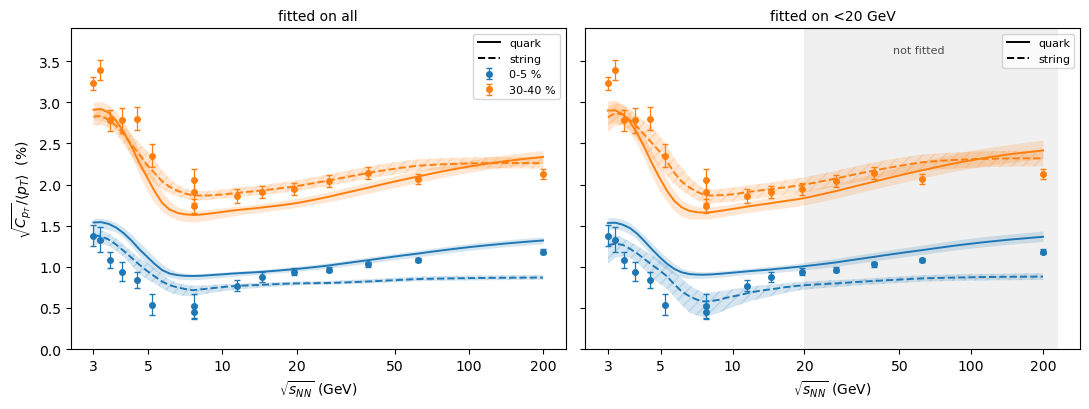

bands are 16-84% of the posterior predictive; solid = quarks, dashed = strings


In [22]:
# ---- posterior-predictive bands for the four runs of the previous cell ----
# Draws the excitation function from the posterior instead of at a single best fit, so the
# width of the band is the actual parameter uncertainty with the yield nuisances marginalised.
assert HAS_JAX and 'runs' in dir(), 'run the NumPyro comparison cell first'
from functools import partial

ED = np.geomspace(3.0, 200.0, 60)
o  = np.argsort(E)
NTOT_ED  = np.interp(np.log(ED), np.log(E[o]), NTOT[o])
NPART_ED = {c: np.interp(np.log(ED), np.log(E[CENT == c]), NPART[CENT == c]) for c in (0, 1)}
NCOLL_ED = {c: np.interp(np.log(ED), np.log(E[CENT == c]), NCOLL[CENT == c]) for c in (0, 1)}

@partial(jax.jit, static_argnums=(5,))
def _curve(p, Etr, w, nu, c_arr, mode_is_quark):
    npart, ncoll, ntot, Ed = c_arr
    f_sat = jnp.full_like(Ed, p) if mode_is_quark else jnp.maximum(1.0, p*ncoll/npart)
    x  = 1.0 + (f_sat - 1.0)/(1.0 + jnp.exp(-(Ed - Etr)/w))
    nb = jnp.clip(ntot/x, 1.0005, None)
    return FWD(x*npart, nb, nu)

def band(mcmc_obj, mode, cent, ndraw=250, seed=0):
    s = mcmc_obj.get_samples()
    key = 'F' if mode == 'quark' else 's'
    n = len(s[key]); idx = np.random.default_rng(seed).choice(n, min(ndraw, n), replace=False)
    arr = (jnp.asarray(NPART_ED[cent]), jnp.asarray(NCOLL_ED[cent]),
           jnp.asarray(NTOT_ED), jnp.asarray(ED))
    cur = np.array([np.asarray(_curve(float(s[key][i]), float(s['Etr'][i]), float(s['w'][i]),
                                      float(s['nu'][i]), arr, mode == 'quark')) for i in idx])
    return np.percentile(cur, [16, 50, 84], axis=0)



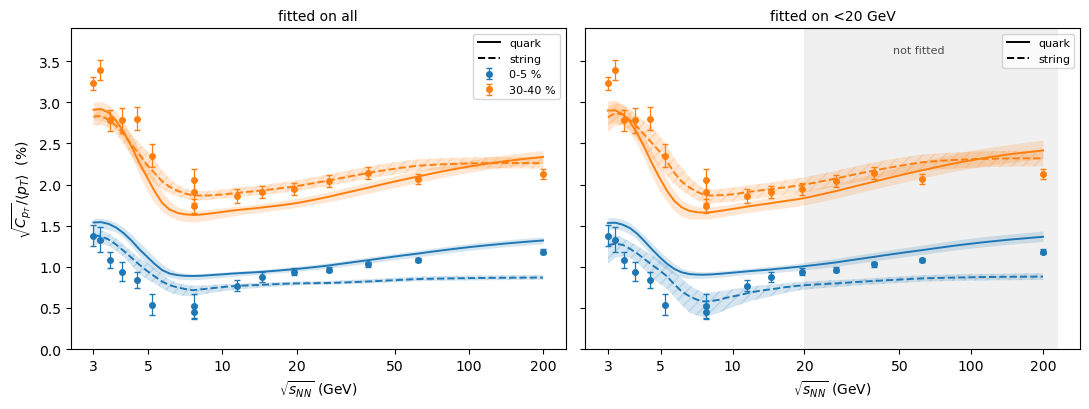

bands are 16-84% of the posterior predictive; solid = quarks, dashed = strings


In [23]:
CC = {0: 'tab:blue', 1: 'tab:orange'}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, rng in zip(axs, ('all', '<20 GeV')):
    for c in (0, 1):
        m = CENT == c
        ax.errorbar(E[m], Y[m], ERR[m], fmt='o', ms=4, color=CC[c], lw=0.9, capsize=2, zorder=6,
                    label=('0-5 %' if c == 0 else '30-40 %') if rng == 'all' else None)
        for mode, hatch, ls in (('quark', None, '-'), ('string', '///', '--')):
            lo, md, hi = band(runs[(mode, rng)], mode, c)
            ax.fill_between(ED, lo, hi, color=CC[c], alpha=0.18, lw=0, hatch=hatch, zorder=2)
            ax.plot(ED, md, ls, color=CC[c], lw=1.4, zorder=3)
    if rng == '<20 GeV':
        ax.axvspan(20, 230, color='k', alpha=0.06, lw=0)
        ax.text(60, 3.6, 'not fitted', fontsize=8, color='0.3', ha='center')
    for mode, ls in (('quark', '-'), ('string', '--')):
        ax.plot([], [], ls, color='k', lw=1.4, label=mode)
    ax.set_xscale('log'); ax.set_xticks([3, 5, 10, 20, 50, 100, 200])
    ax.set_xticklabels(['3', '5', '10', '20', '50', '100', '200']); ax.minorticks_off()
    ax.set_xlabel(r'$\sqrt{s_{NN}}$ (GeV)'); ax.set_ylim(0, 3.9)
    ax.set_title('fitted on %s' % rng, fontsize=10); ax.legend(loc='upper right', fontsize=8)
axs[0].set_ylabel(r'$\sqrt{C_{p_T}}/\langle p_T\rangle$  (%)')
plt.tight_layout(); plt.show()
print('bands are 16-84% of the posterior predictive; solid = quarks, dashed = strings')

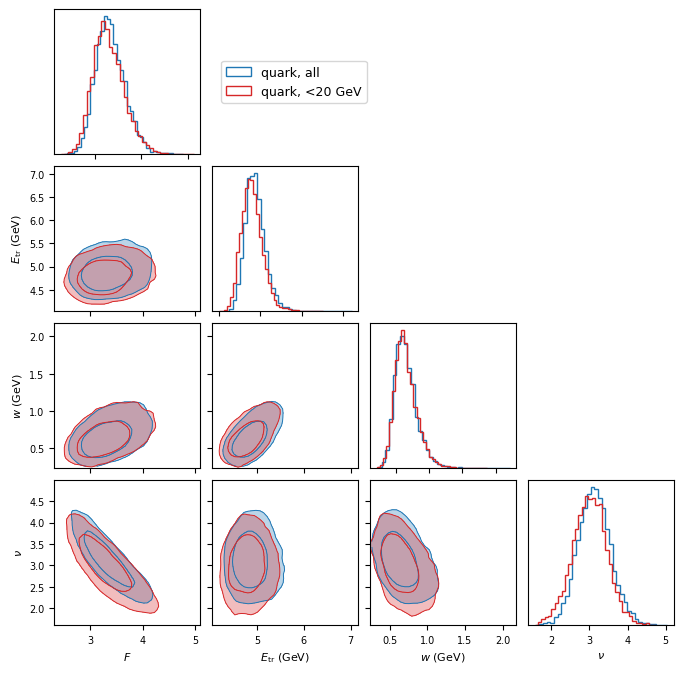

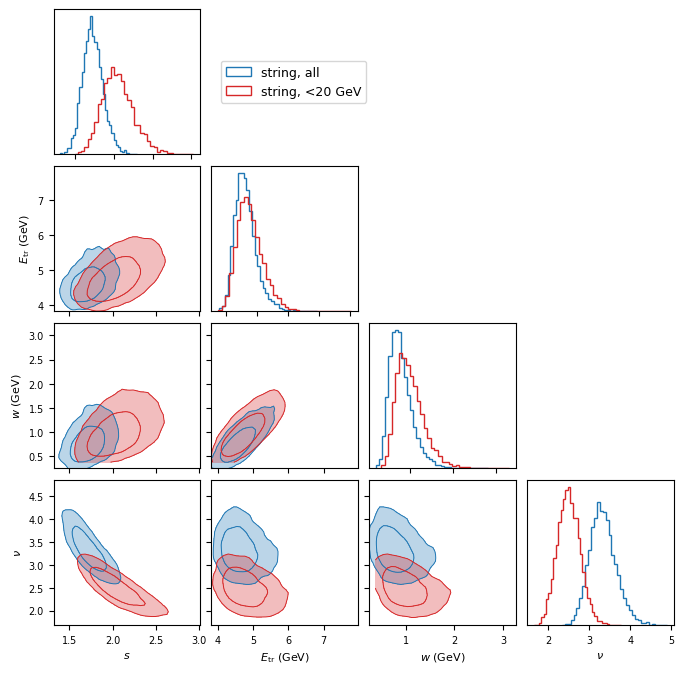

model    range                  f            Etr             nu     Var(q)/<q>^2
quark    all           3.34+-0.32     4.89+-0.25     3.13+-0.43     0.326+-0.047
quark    <20 GeV       3.30+-0.34     4.80+-0.26     3.00+-0.45     0.341+-0.056
string   all           1.72+-0.13     4.64+-0.35     3.33+-0.32     0.303+-0.029
string   <20 GeV       2.05+-0.21     4.79+-0.42     2.50+-0.27     0.405+-0.045

thermal band on Var(q)/<q>^2 is 0.273 - 0.500


In [24]:
# ---- corner plots: how the posterior moves when the range is restricted ----
# Overlays the two energy ranges for each scenario.  Reuses corner_from_samples from Section 4
# but accepts several posteriors at once.
assert HAS_JAX and 'runs' in dir(), 'run the NumPyro comparison cell first'
from scipy.ndimage import gaussian_filter

def corner_overlay(datasets, labels_axis, bins=36, smooth=1.0, figsize=(8, 8)):
    # datasets: list of (list-of-1d-arrays, colour, label)
    d = len(labels_axis)
    def levels(H):
        f = np.sort(H.ravel())[::-1]; c = np.cumsum(f)/f.sum()
        return [f[np.searchsorted(c, q)] for q in (0.95, 0.68)]
    fig, axs = plt.subplots(d, d, figsize=figsize)
    for i in range(d):
        for j in range(d):
            ax = axs[i, j]
            if j > i:
                ax.axis('off'); continue
            for cols, col, lab in datasets:
                if i == j:
                    ax.hist(cols[i], bins=bins, color=col, histtype='step', density=True,
                            label=lab if i == 0 else None)
                    ax.set_yticks([])
                else:
                    H, xe, ye = np.histogram2d(cols[j], cols[i], bins=bins)
                    if smooth: H = gaussian_filter(H, smooth)
                    lv = levels(H)
                    xc, yc = 0.5*(xe[1:]+xe[:-1]), 0.5*(ye[1:]+ye[:-1])
                    ax.contourf(xc, yc, H.T, levels=lv + [H.max()*1.001],
                                colors=[col, col], alpha=0.3)
                    ax.contour(xc, yc, H.T, levels=lv, colors=col, linewidths=0.7)
            if i == d-1: ax.set_xlabel(labels_axis[j], fontsize=8)
            else: ax.set_xticklabels([])
            if j == 0 and i > 0: ax.set_ylabel(labels_axis[i], fontsize=8)
            elif i != j: ax.set_yticklabels([])
            ax.tick_params(labelsize=7)
    axs[0, 0].legend(loc='center left', bbox_to_anchor=(1.1, 0.5), fontsize=9)
    fig.subplots_adjust(wspace=0.08, hspace=0.08)
    return fig

for mode, key, sym in (('quark', 'F', 'F'), ('string', 's', 's')):
    ds = []
    for rng, col in (('all', 'tab:blue'), ('<20 GeV', 'tab:red')):
        s = runs[(mode, rng)].get_samples()
        ds.append(([np.asarray(s[key]), np.asarray(s['Etr']),
                    np.asarray(s['w']), np.asarray(s['nu'])], col, '%s, %s' % (mode, rng)))
    corner_overlay(ds, [r'$%s$' % sym, r'$E_{\rm tr}$ (GeV)', r'$w$ (GeV)', r'$\nu$'])
    plt.show()

print('%-8s %-9s %14s %14s %14s %16s' % ('model', 'range', 'f', 'Etr', 'nu', 'Var(q)/<q>^2'))
for mode, key in (('quark', 'F'), ('string', 's')):
    for rng in ('all', '<20 GeV'):
        s = runs[(mode, rng)].get_samples(); rv = 1.0/np.asarray(s['nu'])
        f = lambda a: '%6.2f+-%.2f' % (np.mean(a), np.std(a))
        print('%-8s %-9s %14s %14s %14s %16s'
              % (mode, rng, f(np.asarray(s[key])), f(np.asarray(s['Etr'])),
                 f(np.asarray(s['nu'])), '%.3f+-%.3f' % (rv.mean(), rv.std())))
print('\nthermal band on Var(q)/<q>^2 is 0.273 - 0.500')

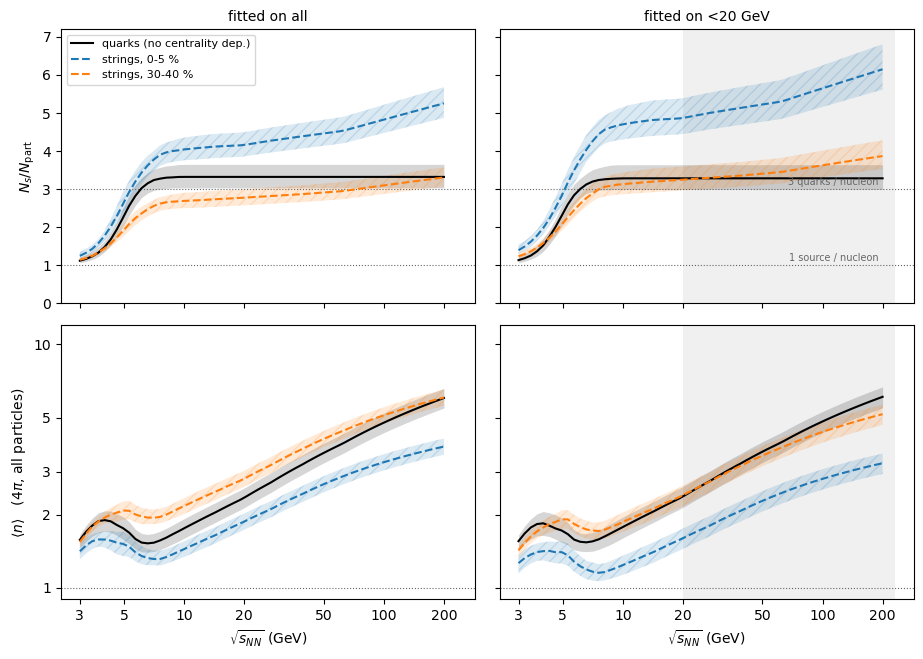

model   range     cent        Ns/Npart(3)  Ns/Npart(200)         <n>(3)       <n>(200)
quark   all       -         1.12 +0.09-0.05  3.32 +0.33-0.29  1.58 +0.08-0.12  6.02 +0.57-0.54
quark   <20 GeV   -         1.13 +0.10-0.07  3.28 +0.36-0.29  1.56 +0.10-0.13  6.09 +0.60-0.60
string  all       0-5 %     1.24 +0.10-0.09  5.25 +0.42-0.38  1.41 +0.11-0.10  3.80 +0.30-0.28
string  all       30-40 %   1.14 +0.06-0.05  3.30 +0.27-0.24  1.54 +0.08-0.08  6.05 +0.48-0.45
string  <20 GeV   0-5 %     1.39 +0.14-0.10  6.15 +0.66-0.53  1.26 +0.10-0.12  3.25 +0.31-0.31
string  <20 GeV   30-40 %   1.23 +0.09-0.06  3.87 +0.41-0.34  1.43 +0.08-0.10  5.17 +0.49-0.50

Ns*<n> = Npart*ntot(E) is imposed, so the two rows carry the same information;
the split between them is what the correlator measures.
The quark scenario predicts Ns/Npart independent of centrality, the string scenario
does not -- that difference, not the energy shape, is the cleanest discriminator.


In [25]:
# ---- posterior bands on N_s/N_part and <n>, for both scenarios and both fit ranges ----
# The companion to the C_pT band cell: same four posteriors, but showing the two latent
# quantities instead of the observable.  Ns and <n> are tied by Ns*<n> = Npart*ntot(E), so the
# lower row is just the upper row inverted -- which is the point: the data fix the product, the
# correlator fixes the split.  Batched over draws with vmap (one kernel, not 250 calls).
assert HAS_JAX and 'runs' in dir(), 'run the NumPyro comparison cell first'
from functools import partial

ED = np.geomspace(3.0, 200.0, 60)
_o = np.argsort(E)
NTOT_ED  = np.interp(np.log(ED), np.log(E[_o]), NTOT[_o])
NPART_ED = {c: np.interp(np.log(ED), np.log(E[CENT == c]), NPART[CENT == c]) for c in (0, 1)}
NCOLL_ED = {c: np.interp(np.log(ED), np.log(E[CENT == c]), NCOLL[CENT == c]) for c in (0, 1)}


def make_sources(mode_is_quark):
    """vmapped over the draw axis: (p, Etr, w) are (ndraw,), the grids are broadcast."""
    def f(p, Etr, w, npart, ncoll, ntot, Ed):
        f_sat = jnp.full_like(Ed, p) if mode_is_quark else jnp.maximum(1.0, p*ncoll/npart)
        x = 1.0 + (f_sat - 1.0)/(1.0 + jnp.exp(-(Ed - Etr)/w))
        return x, jnp.clip(ntot/x, 1.0005, None)
    return jax.jit(jax.vmap(f, in_axes=(0, 0, 0, None, None, None, None)))


SRC = {m: make_sources(m == 'quark') for m in ('quark', 'string')}


def src_band(mcmc_obj, mode, cent, ndraw=400, seed=0):
    s = mcmc_obj.get_samples()
    key = 'F' if mode == 'quark' else 's'
    n = len(s[key]); idx = np.random.default_rng(seed).choice(n, min(ndraw, n), replace=False)
    x, nb = SRC[mode](s[key][idx], s['Etr'][idx], s['w'][idx],
                      jnp.asarray(NPART_ED[cent]), jnp.asarray(NCOLL_ED[cent]),
                      jnp.asarray(NTOT_ED), jnp.asarray(ED))          # (ndraw, 60) each
    q = lambda a: np.percentile(np.asarray(a), [16, 50, 84], axis=0)
    return q(x), q(nb)


CC = {0: 'tab:blue', 1: 'tab:orange'}
CLAB = {0: '0-5 %', 1: '30-40 %'}
fig, axs = plt.subplots(2, 2, figsize=(11, 7.4), sharex=True, sharey='row',
                        gridspec_kw=dict(hspace=0.08, wspace=0.06))
for jc, rng in enumerate(('all', '<20 GeV')):
    for mode, ls, hatch in (('quark', '-', None), ('string', '--', '///')):
        for c in (0, 1):
            # the quark scenario has no centrality dependence at all -- draw it once
            if mode == 'quark' and c == 1:
                continue
            (xl, xm, xh), (nl, nm, nh) = src_band(runs[(mode, rng)], mode, c)
            col = 'k' if mode == 'quark' else CC[c]
            for ax, (lo, md, hi) in zip(axs[:, jc], ((xl, xm, xh), (nl, nm, nh))):
                ax.fill_between(ED, lo, hi, color=col, alpha=0.16, lw=0, hatch=hatch, zorder=2)
                ax.plot(ED, md, ls, color=col, lw=1.5, zorder=3)
    if rng == '<20 GeV':
        for ax in axs[:, jc]:
            ax.axvspan(20, 230, color='k', alpha=0.06, lw=0)
    axs[0, jc].set_title('fitted on %s' % rng, fontsize=10)

# point-by-point extraction from the free random-walk run, if it has been run
if 'sf' in dir():
    _xg, _nt = np.asarray(sf['x_grid']), np.asarray(sf['ntot_grid'])
    for c in (0, 1):
        xl, xm, xh = np.percentile(_xg[:, :, c], [16, 50, 84], axis=0)
        nl, nm, nh = np.percentile(_nt/_xg[:, :, c], [16, 50, 84], axis=0)
        for ax, (lo, md, hi) in zip(axs[:, 0], ((xl, xm, xh), (nl, nm, nh))):
            ax.errorbar(UE, md, [md-lo, hi-md], fmt='o', ms=3.5, color=CC[c], lw=0.8,
                        capsize=2, mfc='w', mew=1.0, zorder=7)

for y, lab in ((1.0, '1 source / nucleon'), (3.0, '3 quarks / nucleon')):
    axs[0, 0].axhline(y, color='0.4', ls=':', lw=0.8)
    axs[0, 1].text(190, y + 0.10, lab, fontsize=7, color='0.4', ha='right')
    axs[0, 1].axhline(y, color='0.4', ls=':', lw=0.8)
axs[1, 0].axhline(1, color='0.4', ls=':', lw=0.8); axs[1, 1].axhline(1, color='0.4', ls=':', lw=0.8)
axs[0, 0].set_ylabel(r'$N_s/N_{\rm part}$'); axs[0, 0].set_ylim(0, 7.2)
axs[1, 0].set_ylabel(r'$\langle n\rangle$   (4$\pi$, all particles)')
axs[1, 0].set_yscale('log'); axs[1, 0].set_ylim(0.9, 12)
axs[1, 0].set_yticks([1, 2, 3, 5, 10]); axs[1, 0].set_yticklabels(['1', '2', '3', '5', '10'])
for ax in axs.ravel():
    ax.set_xscale('log'); ax.set_xticks([3, 5, 10, 20, 50, 100, 200])
    ax.set_xticklabels(['3', '5', '10', '20', '50', '100', '200']); ax.minorticks_off()
for ax in axs[1, :]:
    ax.set_xlabel(r'$\sqrt{s_{NN}}$ (GeV)')
h = [plt.Line2D([], [], ls='-', color='k', lw=1.5, label='quarks (no centrality dep.)'),
     plt.Line2D([], [], ls='--', color=CC[0], lw=1.5, label='strings, 0-5 %'),
     plt.Line2D([], [], ls='--', color=CC[1], lw=1.5, label='strings, 30-40 %')]
if 'sf' in dir():
    h.append(plt.Line2D([], [], ls='', marker='o', ms=3.5, mfc='w', mew=1.0,
                        color=CC[0], label='free $N_s(E)$, per energy'))
axs[0, 0].legend(handles=h, fontsize=8, loc='upper left')
plt.show()

# ---- numbers ----
print('%-7s %-9s %-8s %14s %14s %14s %14s' %
      ('model', 'range', 'cent', 'Ns/Npart(3)', 'Ns/Npart(200)', '<n>(3)', '<n>(200)'))
i3, i200 = 0, len(ED)-1
for mode in ('quark', 'string'):
    for rng in ('all', '<20 GeV'):
        for c in (0, 1):
            if mode == 'quark' and c == 1:
                continue
            (xl, xm, xh), (nl, nm, nh) = src_band(runs[(mode, rng)], mode, c)
            f = lambda m, l, h, i: '%5.2f +%.2f-%.2f' % (m[i], h[i]-m[i], m[i]-l[i])
            print('%-7s %-9s %-8s %14s %14s %14s %14s'
                  % (mode, rng, '-' if mode == 'quark' else CLAB[c],
                     f(xm, xl, xh, i3), f(xm, xl, xh, i200),
                     f(nm, nl, nh, i3), f(nm, nl, nh, i200)))
print('\nNs*<n> = Npart*ntot(E) is imposed, so the two rows carry the same information;')
print('the split between them is what the correlator measures.')
print('The quark scenario predicts Ns/Npart independent of centrality, the string scenario')
print('does not -- that difference, not the energy shape, is the cleanest discriminator.')